Introduction

Social media platforms generate massive volumes of engagement data, including likes, comments, shares, impressions, watch time, and other engagement metrics. Analyzing this data helps companies understand user behaviour, identify trends, evaluate audience engagement, and improve content performance.
In this assignment, we will work with a social media dataset containing various engagement metrics. The project focuses on data cleaning, data transformation, NumPy and Pandas operations, exploratory data analysis (EDA), and data visualization to extract meaningful insights from the dataset.
Through this analysis, we aim to identify engagement patterns, understand user behaviour, compare content performance, and generate valuable insights that support better decision-making in social media management.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

Task 1 — Data Import & Setup
The first task involves importing the social media engagement dataset into Python using the Pandas library. The dataset is examined to understand its structure, columns, and data types. Date columns are converted into the appropriate datetime format for time-based analysis. NumPy arrays are also used to perform basic numerical operations.
Import the CSV dataset using Pandas.
Check and convert data types.
Convert date columns into datetime format.
Perform basic array operations using NumPy.

In [2]:
df = pd.read_csv('social_media_engagement_5000.csv')

Import the CSV dataset using Pandas.

In [3]:
df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372


View the dataset. The head() function displays the first five rows of the dataset.

In [5]:
print("Number of rows and columns:", df.shape)

print("Column Names:")
print(df.columns)

print("Dataset Information:")
df.info()

Number of rows and columns: (5000, 19)
Column Names:
Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate'],
      dtype='str')
Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user_id           5000 non-null   int64  
 1   age               4850 non-null   float64
 2   gender            4850 non-null   str    
 3   country           5000 non-null   str    
 4   post_id           5000 non-null   int64  
 5   post_type         5000 non-null   str    
 6   post_category     5000 non-null   str    
 7   likes             4850 non-null   float64
 8   comments          4850 non-null   float64
 9   shares

shape displays the number of rows and columns.
columns displays all column names.
info() provides information about data types and non-null values.

In [6]:
print("Original Data Types:")
print(df.dtypes)

Original Data Types:
user_id               int64
age                 float64
gender                  str
country                 str
post_id               int64
post_type               str
post_category           str
likes               float64
comments            float64
shares              float64
watch_time_sec        int64
impression_count      int64
posted_at               str
follower_count        int64
is_verified            bool
device_type             str
sentiment               str
hashtags                str
engagement_rate     float64
dtype: object


To convert appropriate numerical columns

In [7]:
numeric_columns = [
    'likes', 'comments', 'shares',
    'impressions', 'watch_time',
    'engagement_rate', 'followers', 'age']

for col in numeric_columns:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')

print(df.dtypes)

user_id               int64
age                 float64
gender                  str
country                 str
post_id               int64
post_type               str
post_category           str
likes               float64
comments            float64
shares              float64
watch_time_sec        int64
impression_count      int64
posted_at               str
follower_count        int64
is_verified            bool
device_type             str
sentiment               str
hashtags                str
engagement_rate     float64
dtype: object


pd.to_numeric() converts selected columns into numerical data types. Invalid values are converted into missing values (NaN) for later cleaning.

In [9]:
date_columns = [
    col for col in df.columns
    if 'date' in col.lower() or 'time' in col.lower()]

print("Date columns converted successfully!")
print(df[date_columns].dtypes)

Date columns converted successfully!
watch_time_sec    datetime64[ns]
sentiment          datetime64[s]
dtype: object


The pd.to_datetime() function converts date-related columns into datetime format, which helps in analyzing daily and time-based engagement trends.

In [10]:
if 'likes' in df.columns:
    likes_array = df['likes'].dropna().to_numpy()

    print("Likes Array:")
    print(likes_array[:10])

    print("Basic Array Operations:")
    print("Sum:", np.sum(likes_array))
    print("Mean:", np.mean(likes_array))
    print("Maximum:", np.max(likes_array))
    print("Minimum:", np.min(likes_array))
    print("Standard Deviation:", np.std(likes_array))

Likes Array:
[ 7011. 11750.  4862.  5350. 12682. 12535. 11703.  9611. 14106.   355.]
Basic Array Operations:
Sum: 49019162.0
Mean: 10107.043711340206
Maximum: 19998.0
Minimum: 10.0
Standard Deviation: 5789.222332204696


NumPy is used to perform numerical operations on the likes data, including sum, mean, maximum, minimum, and standard deviation.

Data Cleaning

Data cleaning is an essential step in data analysis. Raw datasets may contain missing values, duplicate records, incorrect data types, inconsistent categories, and unrealistic values.

In this task, the social media engagement dataset is cleaned and preprocessed to improve its accuracy, consistency, and reliability. Missing values are handled, duplicate records are identified and removed, data formats are standardized, and additional features are extracted for further analysis.
    
- Detect and handle missing values.
- Identify and remove duplicate records.
- Correct incorrect data types and standardize categories.
- Identify and handle unrealistic values.
- Extract hashtag counts and clean sentiment labels.

In [11]:
print("Missing Values:")
print(df.isnull().sum())

print("Total Missing Values:")
print(df.isna().sum().sum())

Missing Values:
user_id                0
age                  150
gender               150
country                0
post_id                0
post_type              0
post_category          0
likes                150
comments             150
shares               150
watch_time_sec         0
impression_count       0
posted_at              0
follower_count         0
is_verified            0
device_type            0
sentiment           5000
hashtags               0
engagement_rate        0
dtype: int64
Total Missing Values:
5750


isnull() identifies missing values in the dataset.
isna() also identifies missing values.
sum() counts the missing values in each column.

In [12]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

print("Missing Value Percentage:")
print(missing_percentage)

Missing Value Percentage:
user_id               0.0
age                   3.0
gender                3.0
country               0.0
post_id               0.0
post_type             0.0
post_category         0.0
likes                 3.0
comments              3.0
shares                3.0
watch_time_sec        0.0
impression_count      0.0
posted_at             0.0
follower_count        0.0
is_verified           0.0
device_type           0.0
sentiment           100.0
hashtags              0.0
engagement_rate       0.0
dtype: float64


This calculates the percentage of missing values in each column.

The median is used to fill missing numerical values because it is less affected by extreme values than the mean.

In [18]:
total_missing = df.isna().sum().sum()

print("Total Missing Values:", total_missing)

Total Missing Values: 5000


The isna() function identifies missing values. It works similarly to isnull().

In [19]:
df_dropna = df.dropna()

print("Original Dataset Shape:", df.shape)
print("After dropna():", df_dropna.shape)

Original Dataset Shape: (5000, 19)
After dropna(): (0, 19)


The dropna() function removes rows containing missing values. Here, we create a separate DataFrame to preserve the original dataset.

In [21]:
df_fillna = df.copy()
df_fillna = df_fillna.fillna("Unknown")
print("Missing values filled successfully.")
print(df_fillna.isnull().sum())

Missing values filled successfully.
user_id             0
age                 0
gender              0
country             0
post_id             0
post_type           0
post_category       0
likes               0
comments            0
shares              0
watch_time_sec      0
impression_count    0
posted_at           0
follower_count      0
is_verified         0
device_type         0
sentiment           0
hashtags            0
engagement_rate     0
dtype: int64


C:\Users\ajith\AppData\Local\Temp\ipykernel_20612\742438851.py:2: Pandas4Warning: 'str' is not supported as a fill value for datetime64[s] dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  df_fillna = df_fillna.fillna("Unknown")


The fillna() function replaces missing values with a specified value. Here, missing entries are temporarily replaced with "Unknown" for demonstration. For numerical columns, we will use statistical methods instead.

In [22]:
df_cleaned = df.copy()

numeric_columns = df_cleaned.select_dtypes(include=np.number).columns

for col in numeric_columns:
    df_cleaned[col] = df_cleaned[col].fillna(
        df_cleaned[col].median()
    )

print("Numerical missing values filled using median.")

Numerical missing values filled using median.


The median is the middle value of a dataset. It is useful for replacing missing numerical values, especially when extreme values are present.

In [23]:
categorical_columns = df_cleaned.select_dtypes(
    include=['object', 'category', 'string']
).columns

for col in categorical_columns:
    if df_cleaned[col].isnull().sum() > 0:
        if not df_cleaned[col].mode().empty:
            df_cleaned[col] = df_cleaned[col].fillna(
                df_cleaned[col].mode()[0]
            )

print("Categorical missing values filled using mode.")

Categorical missing values filled using mode.


Mode is the most frequently occurring value in a column. It is used to replace missing categorical values.

In [24]:
df_forward = df_cleaned.copy()

df_forward = df_forward.ffill()

print("Forward Fill Applied Successfully.")
print(df_forward.isnull().sum())

Forward Fill Applied Successfully.
user_id                0
age                    0
gender                 0
country                0
post_id                0
post_type              0
post_category          0
likes                  0
comments               0
shares                 0
watch_time_sec         0
impression_count       0
posted_at              0
follower_count         0
is_verified            0
device_type            0
sentiment           5000
hashtags               0
engagement_rate        0
dtype: int64


Forward fill replaces missing values with the previous available value in the column. It is useful when the dataset is appropriately ordered and carrying the previous value is meaningful.

In [25]:
df_backward = df_cleaned.copy()

df_backward = df_backward.bfill()

print("Backward Fill Applied Successfully.")
print(df_backward.isnull().sum())

Backward Fill Applied Successfully.
user_id                0
age                    0
gender                 0
country                0
post_id                0
post_type              0
post_category          0
likes                  0
comments               0
shares                 0
watch_time_sec         0
impression_count       0
posted_at              0
follower_count         0
is_verified            0
device_type            0
sentiment           5000
hashtags               0
engagement_rate        0
dtype: int64


Backward fill replaces missing values with the next available value in the column.

In [27]:
print("Missing Values After Cleaning:")
print(df_cleaned.isnull().sum())

print("Total Remaining Missing Values:")
print(df_cleaned.isnull().sum().sum())

Missing Values After Cleaning:
user_id                0
age                    0
gender                 0
country                0
post_id                0
post_type              0
post_category          0
likes                  0
comments               0
shares                 0
watch_time_sec         0
impression_count       0
posted_at              0
follower_count         0
is_verified            0
device_type            0
sentiment           5000
hashtags               0
engagement_rate        0
dtype: int64
Total Remaining Missing Values:
5000


This checks whether missing values remain after applying the selected cleaning methods.

Duplicate Handling

Duplicate records are repeated entries in a dataset. They can affect the accuracy of analysis and lead to incorrect results. Therefore, duplicate records must be identified and removed.

In [28]:
print("Total Duplicate Records:")
print(df_cleaned.duplicated().sum())

Total Duplicate Records:
0


The duplicated() function identifies repeated rows in the dataset. The sum() function counts the total number of duplicate records.

In [29]:


duplicates = df_cleaned[df_cleaned.duplicated()]

print("Duplicate Records:")
display(duplicates)

Duplicate Records:


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate


This code displays all duplicate rows identified in the dataset.

In [30]:
df_cleaned = df_cleaned.drop_duplicates()

print("Duplicate records removed successfully!")

print("Updated Dataset Shape:", df_cleaned.shape)

Duplicate records removed successfully!
Updated Dataset Shape: (5000, 19)


The drop_duplicates() function removes repeated records while keeping the first occurrence of each unique row.

In [31]:

print("Remaining Duplicate Records:")
print(df_cleaned.duplicated().sum())

Remaining Duplicate Records:
0


output will be 0

Data Formatting

Data formatting is the process of correcting incorrect data types and maintaining consistency in the dataset. It helps ensure that the data is stored in the proper format for further analysis.

In [32]:
print("Data Types Before Formatting:")
print(df_cleaned.dtypes)

Data Types Before Formatting:
user_id                      int64
age                        float64
gender                         str
country                        str
post_id                      int64
post_type                      str
post_category                  str
likes                      float64
comments                   float64
shares                     float64
watch_time_sec      datetime64[ns]
impression_count             int64
posted_at                      str
follower_count               int64
is_verified                   bool
device_type                    str
sentiment            datetime64[s]
hashtags                       str
engagement_rate            float64
dtype: object


The dtypes attribute displays the data type of each column in the dataset.

In [33]:
columns_to_convert = ['likes', 'comments', 'shares']

for col in columns_to_convert:
    if col in df_cleaned.columns:
        df_cleaned[col] = pd.to_numeric(
            df_cleaned[col], errors='coerce'
        )

print("Data types converted successfully!")
print(df_cleaned[columns_to_convert].dtypes)

Data types converted successfully!
likes       float64
comments    float64
shares      float64
dtype: object


The pd.to_numeric() function converts the selected columns into numerical format. Invalid values are converted into missing values (NaN).

In [34]:

if 'gender' in df_cleaned.columns:

    df_cleaned['gender'] = (
        df_cleaned['gender']
        .astype('string')
        .str.strip()
        .str.lower())

    gender_mapping = {
        'm': 'male',
        'f': 'female'}

    df_cleaned['gender'] = df_cleaned['gender'].replace(
        gender_mapping)

    print("Standardized Gender Categories:")
    print(df_cleaned['gender'].value_counts())

else:
    print("Gender column not found.")

Standardized Gender Categories:
gender
male      1849
other     1581
female    1570
Name: count, dtype: Int64


str.strip() removes unnecessary spaces.
str.lower() converts text into lowercase.
replace() standardizes abbreviations such as M and F.

In [35]:
columns_to_check = ['likes', 'comments', 'shares']

for col in columns_to_check:
    if col in df_cleaned.columns:
        print(f"\nNegative values in {col}:")
        print((df_cleaned[col] < 0).sum())


Negative values in likes:
0

Negative values in comments:
0

Negative values in shares:
0


This code identifies negative values in likes, comments, and shares.

In [36]:
for col in columns_to_check:
    if col in df_cleaned.columns:
        df_cleaned.loc[df_cleaned[col] < 0, col] = np.nan

print("Unrealistic values handled successfully!")

Unrealistic values handled successfully!


Negative values are replaced with NaN because they are not valid engagement counts. They can then be handled using suitable missing-value techniques.

In [38]:
for col in columns_to_check:
    if col in df_cleaned.columns:
        print(f"n{col}:")
        print("Negative values remaining:",
              (df_cleaned[col] < 0).sum())

nlikes:
Negative values remaining: 0
ncomments:
Negative values remaining: 0
nshares:
Negative values remaining: 0


The number of negative values should be zero for each available engagement column.

Feature Cleaning

Feature cleaning involves extracting useful information from existing columns and improving the consistency of textual data. In this section, we extract hashtag counts and clean sentiment labels.

In [39]:


print("Available Columns:")
print(df_cleaned.columns.tolist())

Available Columns:
['user_id', 'age', 'gender', 'country', 'post_id', 'post_type', 'post_category', 'likes', 'comments', 'shares', 'watch_time_sec', 'impression_count', 'posted_at', 'follower_count', 'is_verified', 'device_type', 'sentiment', 'hashtags', 'engagement_rate']


Now extract the hashtag count. The following code checks common text-column names.

In [40]:


text_columns = ['hashtags', 'caption', 'post_text', 'content', 'text']

text_col = next(
    (col for col in text_columns if col in df_cleaned.columns),
    None)

if text_col is not None:

    df_cleaned['hashtag_count'] = (
        df_cleaned[text_col]
        .fillna('')
        .astype(str)
        .str.count(r'#\w+'))

    print("Hashtag Count Extracted Successfully!")

    display(df_cleaned[[text_col, 'hashtag_count']].head())

else:
    print("No suitable text column found. Check the column names.")

Hashtag Count Extracted Successfully!


,hashtags,hashtag_count
0,#foodie #travel #love,3
1,#fitness,1
2,#foodie,1
3,#music #foodie #fun,3
4,#travel,1


fillna('') replaces missing text with an empty string.

str.count(r'#\w+') counts the hashtags in each post.

A new column called hashtag_count is created.

In [41]:
if 'sentiment' in df_cleaned.columns:

    df_cleaned['sentiment'] = (
        df_cleaned['sentiment']
        .astype('string')
        .str.strip()
        .str.lower())

    print("Sentiment Labels Cleaned Successfully!")

    print("\nSentiment Distribution:")
    print(df_cleaned['sentiment'].value_counts())

else:
    print("Sentiment column not found.")

Sentiment Labels Cleaned Successfully!

Sentiment Distribution:
Series([], Name: count, dtype: Int64)


str.strip() removes unnecessary spaces.
str.lower() converts all sentiment labels into lowercase.
value_counts() displays the frequency of each sentiment category.

In [43]:
print("Unique Sentiment Labels:")
print(df_cleaned['sentiment'].unique())

Unique Sentiment Labels:
<StringArray>
[<NA>]
Length: 1, dtype: string


The unique() function displays all distinct sentiment categories after cleaning.

In [44]:
display(df_cleaned.head())

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
0,25795,43.0,female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,1970-01-01 00:00:00.000005726,44650,17-12-2022,81734,False,mobile,<NA>,#foodie #travel #love,0.190862,3
1,10860,33.0,male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,1970-01-01 00:00:00.000005947,80216,02-06-2023,5963,False,mobile,<NA>,#fitness,0.201493,1
2,86820,32.0,female,UK,109864,text,food,4862.0,344.0,955.0,1970-01-01 00:00:00.000006946,44858,07-05-2023,501783,False,tablet,<NA>,#foodie,0.137345,1
3,64886,51.0,other,France,848877,text,fitness,5350.0,1083.0,1049.0,1970-01-01 00:00:00.000000229,70455,12-02-2023,480212,False,mobile,<NA>,#music #foodie #fun,0.106195,3
4,16265,34.0,other,UK,449706,image,fitness,12682.0,2735.0,1300.0,1970-01-01 00:00:00.000004798,6019,23-05-2023,383936,False,mobile,<NA>,#travel,2.777372,1


In [45]:
print("Final Dataset Shape:", df_cleaned.shape)

print("Data Types:")
print(df_cleaned.dtypes)

print("Missing Values:")
print(df_cleaned.isnull().sum())

print("Duplicate Records:")
print(df_cleaned.duplicated().sum())

Final Dataset Shape: (5000, 20)

Data Types:
user_id                      int64
age                        float64
gender                      string
country                        str
post_id                      int64
post_type                      str
post_category                  str
likes                      float64
comments                   float64
shares                     float64
watch_time_sec      datetime64[ns]
impression_count             int64
posted_at                      str
follower_count               int64
is_verified                   bool
device_type                    str
sentiment                   string
hashtags                       str
engagement_rate            float64
hashtag_count                int64
dtype: object

Missing Values:
user_id                0
age                    0
gender                 0
country                0
post_id                0
post_type              0
post_category          0
likes                  0
comments               0

Social media dataset was cleaned and preprocessed by identifying and handling missing values, removing duplicate records, correcting data types, standardizing gender categories, and handling unrealistic engagement values. Hashtag counts were extracted, and sentiment labels were standardized. These steps improved the consistency and quality of the dataset, making it suitable for further data exploration and analysis.

Data Exploration using Pandas

In this task, we will explore the cleaned social media dataset to understand its structure, data types, statistical information, categorical distributions, correlations, and group-wise summaries.

In [46]:
display(df_cleaned.head())

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
0,25795,43.0,female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,1970-01-01 00:00:00.000005726,44650,17-12-2022,81734,False,mobile,<NA>,#foodie #travel #love,0.190862,3
1,10860,33.0,male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,1970-01-01 00:00:00.000005947,80216,02-06-2023,5963,False,mobile,<NA>,#fitness,0.201493,1
2,86820,32.0,female,UK,109864,text,food,4862.0,344.0,955.0,1970-01-01 00:00:00.000006946,44858,07-05-2023,501783,False,tablet,<NA>,#foodie,0.137345,1
3,64886,51.0,other,France,848877,text,fitness,5350.0,1083.0,1049.0,1970-01-01 00:00:00.000000229,70455,12-02-2023,480212,False,mobile,<NA>,#music #foodie #fun,0.106195,3
4,16265,34.0,other,UK,449706,image,fitness,12682.0,2735.0,1300.0,1970-01-01 00:00:00.000004798,6019,23-05-2023,383936,False,mobile,<NA>,#travel,2.777372,1


The head() function displays the first five rows of the dataset. It helps us understand the type of information stored in each column.

In [47]:
display(df_cleaned.tail())

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
4995,59500,44.0,male,Australia,441541,video,education,16210.0,2013.0,1837.0,1970-01-01 00:00:00.000006190,42977,25-06-2022,646147,False,mobile,<NA>,#travel #fun,0.466761,2
4996,22100,38.0,other,UAE,677076,reel,education,16924.0,2734.0,1583.0,1970-01-01 00:00:00.000007764,34196,18-11-2022,584603,False,desktop,<NA>,#foodie #reels,0.621155,2
4997,67021,63.0,female,USA,273595,text,travel,13487.0,1497.0,167.0,1970-01-01 00:00:00.000007466,23680,06-04-2023,483550,False,desktop,<NA>,#lifestyle #tech,0.679688,2
4998,29800,13.0,female,Germany,785644,video,fitness,16894.0,1289.0,1713.0,1970-01-01 00:00:00.000004991,89013,16-05-2022,183295,False,tablet,<NA>,#reels #love #fitness,0.223518,3
4999,73400,54.0,other,Japan,712252,text,travel,14830.0,503.0,1798.0,1970-01-01 00:00:00.000003743,14234,04-03-2023,585760,False,desktop,<NA>,#foodie #lifestyle #fashion,1.203527,3


The tail() function displays the last five rows of the dataset.

In [48]:
print("Dataset Shape:", df_cleaned.shape)

print("Number of Rows:", df_cleaned.shape[0])

print("Number of Columns:", df_cleaned.shape[1])

Dataset Shape: (5000, 20)
Number of Rows: 5000
Number of Columns: 20


shape returns the dimensions of the dataset.
shape[0] gives the total number of rows.
shape[1] gives the total number of columns.

In [50]:
print("Column Names:")
print(df_cleaned.columns.tolist())

Column Names:
['user_id', 'age', 'gender', 'country', 'post_id', 'post_type', 'post_category', 'likes', 'comments', 'shares', 'watch_time_sec', 'impression_count', 'posted_at', 'follower_count', 'is_verified', 'device_type', 'sentiment', 'hashtags', 'engagement_rate', 'hashtag_count']


The columns attribute displays the names of all columns in the dataset.

In [51]:
df_cleaned.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           5000 non-null   int64         
 1   age               5000 non-null   float64       
 2   gender            5000 non-null   string        
 3   country           5000 non-null   str           
 4   post_id           5000 non-null   int64         
 5   post_type         5000 non-null   str           
 6   post_category     5000 non-null   str           
 7   likes             5000 non-null   float64       
 8   comments          5000 non-null   float64       
 9   shares            5000 non-null   float64       
 10  watch_time_sec    5000 non-null   datetime64[ns]
 11  impression_count  5000 non-null   int64         
 12  posted_at         5000 non-null   str           
 13  follower_count    5000 non-null   int64         
 14  is_verified       5000 non-null   b

The info() function displays the number of entries, column names, non-null values, data types, and memory usage.

In [53]:
print("Data Types of Each Column:")
print(df_cleaned.dtypes)

Data Types of Each Column:
user_id                      int64
age                        float64
gender                      string
country                        str
post_id                      int64
post_type                      str
post_category                  str
likes                      float64
comments                   float64
shares                     float64
watch_time_sec      datetime64[ns]
impression_count             int64
posted_at                      str
follower_count               int64
is_verified                   bool
device_type                    str
sentiment                   string
hashtags                       str
engagement_rate            float64
hashtag_count                int64
dtype: object


The dtypes attribute displays the data type of each column, such as integer, float, object, and datetime.

In [54]:
display(df_cleaned.describe())

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,follower_count,engagement_rate,hashtag_count
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.0000,5000,5000.000000,5000.000000,5000.000000,5000.000000
mean,54561.890800,38.440400,548042.909000,10106.997400,1502.039800,1002.9106,1970-01-01 00:00:00.000004014,50013.732800,393698.224800,0.964356,1.998600
min,10055.000000,13.000000,100068.000000,10.000000,0.000000,0.0000,1970-01-01 00:00:00,105.000000,87.000000,0.006363,1.000000
25%,32309.500000,26.000000,322543.500000,5235.000000,792.000000,511.0000,1970-01-01 00:00:00.000002017,24988.250000,194480.000000,0.145781,1.000000
50%,54374.500000,38.000000,548077.500000,10105.500000,1497.000000,1012.0000,1970-01-01 00:00:00.000004034,49934.500000,388982.000000,0.253896,2.000000
75%,77180.500000,51.000000,771574.500000,14959.000000,2235.250000,1483.0000,1970-01-01 00:00:00.000006020,74662.250000,589744.250000,0.504794,3.000000
max,99963.000000,64.000000,999455.000000,19998.000000,2999.000000,1999.0000,1970-01-01 00:00:00.000007998,99995.000000,799533.000000,191.504348,3.000000
std,26090.370121,14.687151,260646.957267,5702.293017,856.393312,570.8552,NaN,28844.939104,230927.884535,5.318029,0.812853


The describe() function provides the following statistical measures:
- Count – Number of non-missing values.
- Mean – Average value.
- Std – Standard deviation.
- Min – Minimum value.
- 25% – First quartile.
- 50% – Median.
- 75% – Third quartile.
- Max – Maximum value.

In [55]:
display(df_cleaned.describe(include='object'))

C:\Users\ajith\AppData\Local\Temp\ipykernel_20612\3041472946.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df_cleaned.describe(include='object'))


,country,post_type,post_category,posted_at,device_type,hashtags
count,5000,5000,5000,5000,5000,5000
unique,10,4,8,729,3,761
top,India,reel,fitness,26-12-2023,mobile,#tech
freq,535,1283,675,16,1684,201


This displays categorical information, including the number of unique values, most frequent value, and its frequency.

In [56]:
if 'post_type' in df_cleaned.columns:
    print("Post Type Distribution:")
    print(df_cleaned['post_type'].value_counts())
else:
    print("post_type column not found.")

Post Type Distribution:
post_type
reel     1283
image    1247
text     1245
video    1225
Name: count, dtype: int64


The value_counts() function counts the number of occurrences of each post type.

In [57]:
if 'post_type' in df_cleaned.columns:
    print("Unique Post Types:")
    print(df_cleaned['post_type'].unique())

Unique Post Types:
<StringArray>
['image', 'reel', 'text', 'video']
Length: 4, dtype: str


The unique() function displays all distinct categories present in a column.

In [58]:
if 'post_type' in df_cleaned.columns:
    print("Number of Unique Post Types:")
    print(df_cleaned['post_type'].nunique())

Number of Unique Post Types:
4


The nunique() function returns the total number of unique categories.

In [59]:
categorical_columns = [
    'gender', 'country', 'sentiment',
    'device_type', 'category'
]

for col in categorical_columns:
    if col in df_cleaned.columns:
        print(f"\nDistribution of {col}:")
        print(df_cleaned[col].value_counts())


Distribution of gender:
gender
male      1849
other     1581
female    1570
Name: count, dtype: Int64

Distribution of country:
country
India        535
Canada       513
Brazil       504
UAE          503
USA          501
France       496
UK           493
Australia    493
Germany      490
Japan        472
Name: count, dtype: int64

Distribution of sentiment:
Series([], Name: count, dtype: Int64)

Distribution of device_type:
device_type
mobile     1684
tablet     1658
desktop    1658
Name: count, dtype: int64


This code analyzes the frequency distribution of available categorical columns, such as gender, country, sentiment, device type, and category.

In [60]:
numeric_data = df_cleaned.select_dtypes(include=np.number)

# Create correlation matrix

correlation_matrix = numeric_data.corr()

print("Correlation Matrix:")
display(correlation_matrix)

Correlation Matrix:


,user_id,age,post_id,likes,comments,shares,impression_count,follower_count,engagement_rate,hashtag_count
user_id,1.000000,-0.006688,0.020051,0.025811,-0.033395,0.013763,0.015326,0.010124,-0.004282,-0.013692
age,-0.006688,1.000000,-0.013153,-0.036322,-0.007284,0.013871,0.013322,-0.024894,0.008039,0.007173
post_id,0.020051,-0.013153,1.000000,0.014526,-0.010540,0.001846,-0.007709,-0.002844,0.010139,0.007344
likes,0.025811,-0.036322,0.014526,1.000000,-0.018421,0.004712,0.007952,-0.022982,0.093520,-0.002190
comments,-0.033395,-0.007284,-0.010540,-0.018421,1.000000,0.006142,-0.009395,-0.011733,0.000051,-0.015230
shares,0.013763,0.013871,0.001846,0.004712,0.006142,1.000000,-0.005204,-0.010783,0.021724,0.013379
impression_count,0.015326,0.013322,-0.007709,0.007952,-0.009395,-0.005204,1.000000,-0.015513,-0.232226,-0.002714
follower_count,0.010124,-0.024894,-0.002844,-0.022982,-0.011733,-0.010783,-0.015513,1.000000,0.002292,0.008802
engagement_rate,-0.004282,0.008039,0.010139,0.093520,0.000051,0.021724,-0.232226,0.002292,1.000000,0.005319
hashtag_count,-0.013692,0.007173,0.007344,-0.002190,-0.015230,0.013379,-0.002714,0.008802,0.005319,1.000000


The corr() function calculates the correlation between numerical columns. Correlation values range from -1 to +1.

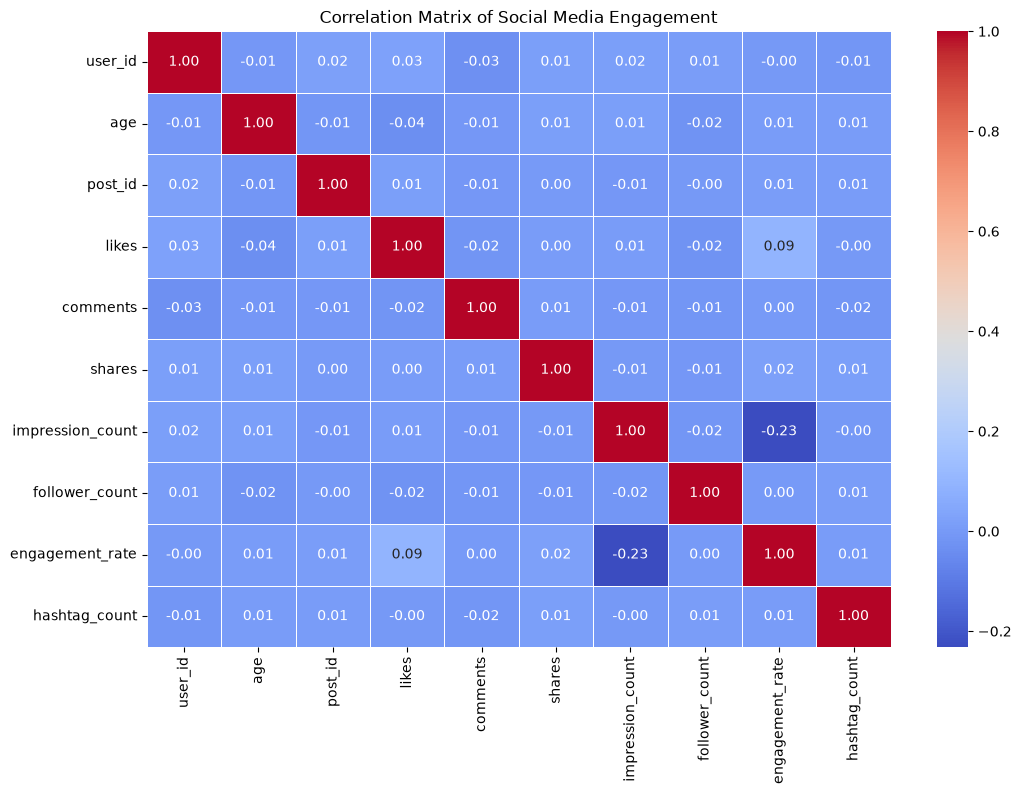

In [61]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Correlation Matrix of Social Media Engagement")
plt.show()

A heatmap represents correlation values using different shades of colour. It helps us identify positive and negative relationships between numerical variables.

In [62]:
if 'post_type' in df_cleaned.columns and 'likes' in df_cleaned.columns:

    avg_likes = df_cleaned.groupby('post_type')['likes'].mean()

    print("Average Likes by Post Type:")
    display(avg_likes)

Average Likes by Post Type:


post_type
image    10104.865277
reel     10037.802416
text     10100.148193
video    10188.600000
Name: likes, dtype: float64

This code groups the dataset according to post type and calculates the average number of likes for each type.

In [63]:
if 'country' in df_cleaned.columns and 'impressions' in df_cleaned.columns:

    country_impressions = df_cleaned.groupby('country')['impressions'].sum()

    print("Total Impressions by Country:")
    display(country_impressions.sort_values(ascending=False))

This code groups the dataset by country and calculates the total impressions for each country. The results are arranged in descending order.

In [64]:
if 'country' in df_cleaned.columns and 'engagement_rate' in df_cleaned.columns:

    country_engagement = df_cleaned.groupby('country')['engagement_rate'].mean()

    print("Average Engagement Rate by Country:")
    display(country_engagement.sort_values(ascending=False))

Average Engagement Rate by Country:


country
Brazil       1.540704
Australia    1.324339
France       1.146402
UAE          1.112352
Canada       0.916659
UK           0.850966
Japan        0.769623
Germany      0.759000
India        0.655005
USA          0.576580
Name: engagement_rate, dtype: float64

This analysis compares the average engagement rate across different countries.

In [65]:
if 'sentiment' in df_cleaned.columns:

    sentiment_analysis = df_cleaned.groupby('sentiment').agg({
        'likes': 'mean',
        'comments': 'mean',
        'shares': 'mean' })

    print("Engagement Analysis by Sentiment:")
    display(sentiment_analysis)

Engagement Analysis by Sentiment:


,likes,comments,shares
sentiment,,,


This code groups social media posts according to sentiment and calculates the average likes, comments, and shares for each sentiment category.

This task helped develop a better understanding of the dataset and identify important patterns and relationships that can be explored further through data wrangling, statistical analysis, and visualization.

Data wrangling is the process of transforming and organizing data into a suitable format for analysis. In this task, new columns are created from existing data, different DataFrames can be combined when required, and groupby operations are performed to summarize social media engagement. These steps help us understand the performance of different post types, countries, and sentiment categories.

In [66]:
df_part1 = df_cleaned.head(5)
df_part2 = df_cleaned.tail(5)

combined_df = pd.concat([df_part1, df_part2], ignore_index=True)

print("Combined DataFrame:")
display(combined_df)

Combined DataFrame:


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
0,25795,43.0,female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,1970-01-01 00:00:00.000005726,44650,17-12-2022,81734,False,mobile,<NA>,#foodie #travel #love,0.190862,3
1,10860,33.0,male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,1970-01-01 00:00:00.000005947,80216,02-06-2023,5963,False,mobile,<NA>,#fitness,0.201493,1
2,86820,32.0,female,UK,109864,text,food,4862.0,344.0,955.0,1970-01-01 00:00:00.000006946,44858,07-05-2023,501783,False,tablet,<NA>,#foodie,0.137345,1
3,64886,51.0,other,France,848877,text,fitness,5350.0,1083.0,1049.0,1970-01-01 00:00:00.000000229,70455,12-02-2023,480212,False,mobile,<NA>,#music #foodie #fun,0.106195,3
4,16265,34.0,other,UK,449706,image,fitness,12682.0,2735.0,1300.0,1970-01-01 00:00:00.000004798,6019,23-05-2023,383936,False,mobile,<NA>,#travel,2.777372,1
5,59500,44.0,male,Australia,441541,video,education,16210.0,2013.0,1837.0,1970-01-01 00:00:00.000006190,42977,25-06-2022,646147,False,mobile,<NA>,#travel #fun,0.466761,2
6,22100,38.0,other,UAE,677076,reel,education,16924.0,2734.0,1583.0,1970-01-01 00:00:00.000007764,34196,18-11-2022,584603,False,desktop,<NA>,#foodie #reels,0.621155,2
7,67021,63.0,female,USA,273595,text,travel,13487.0,1497.0,167.0,1970-01-01 00:00:00.000007466,23680,06-04-2023,483550,False,desktop,<NA>,#lifestyle #tech,0.679688,2
8,29800,13.0,female,Germany,785644,video,fitness,16894.0,1289.0,1713.0,1970-01-01 00:00:00.000004991,89013,16-05-2022,183295,False,tablet,<NA>,#reels #love #fitness,0.223518,3
9,73400,54.0,other,Japan,712252,text,travel,14830.0,503.0,1798.0,1970-01-01 00:00:00.000003743,14234,04-03-2023,585760,False,desktop,<NA>,#foodie #lifestyle #fashion,1.203527,3


head(5) selects the first five rows.
tail(5) selects the last five rows.
pd.concat() combines both DataFrames.
ignore_index=True creates a new continuous index.

In [67]:

required_columns = ['likes', 'comments', 'shares']

if all(col in df_cleaned.columns for col in required_columns):

    df_cleaned['engagement_score'] = (
        df_cleaned['likes'] +
        df_cleaned['comments'] +
        df_cleaned['shares']
    )

    print("Engagement Score Created Successfully!")
    display(df_cleaned[['likes', 'comments', 'shares', 'engagement_score']].head())

else:
    print("Required engagement columns are not available.")

Engagement Score Created Successfully!


,likes,comments,shares,engagement_score
0,7011.0,354.0,1157.0,8522.0
1,11750.0,2606.0,1807.0,16163.0
2,4862.0,344.0,955.0,6161.0
3,5350.0,1083.0,1049.0,7482.0
4,12682.0,2735.0,1300.0,16717.0


Log transformation reduces the effect of very large values and can make numerical data easier to analyze.

In [68]:
for col in ['likes', 'comments', 'shares', 'impressions']:

    if col in df_cleaned.columns:

        df_cleaned['log_' + col] = np.log1p(df_cleaned[col])

print("Log-transformed columns created successfully!")
display(df_cleaned.head())

Log-transformed columns created successfully!


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,...,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count,engagement_score,log_likes,log_comments,log_shares
0,25795,43.0,female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,...,False,mobile,<NA>,#foodie #travel #love,0.190862,3,8522.0,8.855378,5.872118,7.054450
1,10860,33.0,male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,...,False,mobile,<NA>,#fitness,0.201493,1,16163.0,9.371694,7.865955,7.499977
2,86820,32.0,female,UK,109864,text,food,4862.0,344.0,955.0,...,False,tablet,<NA>,#foodie,0.137345,1,6161.0,8.489411,5.843544,6.862758
3,64886,51.0,other,France,848877,text,fitness,5350.0,1083.0,1049.0,...,False,mobile,<NA>,#music #foodie #fun,0.106195,3,7482.0,8.585039,6.988413,6.956545
4,16265,34.0,other,UK,449706,image,fitness,12682.0,2735.0,1300.0,...,False,mobile,<NA>,#travel,2.777372,1,16717.0,9.448018,7.914252,7.170888


np.log1p() is used because it calculates log(1 + value), so it can also handle zero values.

In [69]:
text_columns = ['hashtags', 'caption', 'post_text', 'content', 'text']

text_column = next(
    (col for col in text_columns if col in df_cleaned.columns),
    None)

if text_column:

    df_cleaned['hashtag_count'] = (
        df_cleaned[text_column]
        .fillna('')
        .astype(str)
        .str.count(r'#\w+'))

    print("Hashtag Count Created Successfully!")
    display(df_cleaned[[text_column, 'hashtag_count']].head())

Hashtag Count Created Successfully!


,hashtags,hashtag_count
0,#foodie #travel #love,3
1,#fitness,1
2,#foodie,1
3,#music #foodie #fun,3
4,#travel,1


The groupby() function divides data into groups based on a particular column and helps calculate summary values for each group.

In [70]:
if 'post_type' in df_cleaned.columns and 'engagement_score' in df_cleaned.columns:

    post_type_summary = df_cleaned.groupby('post_type')['engagement_score'].mean()

    print("Average Engagement Score by Post Type:")
    display(post_type_summary)

else:
    print("Required columns are not available.")

Average Engagement Score by Post Type:


post_type
image    12649.390537
reel     12524.031567
text     12613.243775
video    12664.594286
Name: engagement_score, dtype: float64

In [71]:
if 'country' in df_cleaned.columns and 'engagement_score' in df_cleaned.columns:

    country_summary = df_cleaned.groupby('country')['engagement_score'].mean()

    print("Average Engagement Score by Country:")
    display(country_summary)

else:
    print("Required columns are not available.")

Average Engagement Score by Country:


country
Australia    12809.621704
Brazil       12385.983135
Canada       12605.894737
France       12903.384073
Germany      12635.664286
India        12492.701869
Japan        12578.648305
UAE          12757.777336
UK           12384.374239
USA          12575.461078
Name: engagement_score, dtype: float64

In [72]:
if 'sentiment' in df_cleaned.columns and 'engagement_score' in df_cleaned.columns:

    sentiment_summary = df_cleaned.groupby('sentiment')['engagement_score'].mean()

    print("Average Engagement Score by Sentiment:")
    display(sentiment_summary)

else:
    print("Required columns are not available.")

Average Engagement Score by Sentiment:


Series([], Name: engagement_score, dtype: float64)

In [73]:
print("Updated Dataset:")
display(df_cleaned.head())

print("Dataset Shape:", df_cleaned.shape)

Updated Dataset:


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,...,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count,engagement_score,log_likes,log_comments,log_shares
0,25795,43.0,female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,...,False,mobile,<NA>,#foodie #travel #love,0.190862,3,8522.0,8.855378,5.872118,7.054450
1,10860,33.0,male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,...,False,mobile,<NA>,#fitness,0.201493,1,16163.0,9.371694,7.865955,7.499977
2,86820,32.0,female,UK,109864,text,food,4862.0,344.0,955.0,...,False,tablet,<NA>,#foodie,0.137345,1,6161.0,8.489411,5.843544,6.862758
3,64886,51.0,other,France,848877,text,fitness,5350.0,1083.0,1049.0,...,False,mobile,<NA>,#music #foodie #fun,0.106195,3,7482.0,8.585039,6.988413,6.956545
4,16265,34.0,other,UK,449706,image,fitness,12682.0,2735.0,1300.0,...,False,mobile,<NA>,#travel,2.777372,1,16717.0,9.448018,7.914252,7.170888


Dataset Shape: (5000, 24)


To organize and transform the social media engagement dataset. DataFrames were combined using concatenation, and new columns such as engagement score, log-transformed metrics, and hashtag count were created where the required source columns were available. Groupby operations were also performed based on post type, country, and sentiment to understand engagement patterns. These steps prepare the dataset for further statistical analysis and visualization.

Statistical analysis is used to understand the distribution and characteristics of numerical data. In this task, we perform descriptive statistical analysis on social media engagement metrics such as likes, comments, shares, watch time, engagement rate, and followers.

In [74]:
cols = ["likes", "comments", "shares", "watch_time_sec",
        "engagement_rate", "follower_count"]

In [82]:
numeric_df = df[cols].select_dtypes(include='number')

numeric_df.head()

,likes,comments,shares,engagement_rate,follower_count
0,7011.0,354.0,1157.0,0.190862,81734
1,11750.0,2606.0,1807.0,0.201493,5963
2,4862.0,344.0,955.0,0.137345,501783
3,5350.0,1083.0,1049.0,0.106195,480212
4,12682.0,2735.0,1300.0,2.777372,383936


In [86]:

numeric_df.mean()


likes               10106.997400
comments             1502.039800
shares               1002.910600
engagement_rate         0.964356
follower_count     393698.224800
dtype: float64

In [87]:
numeric_df.median()



likes               10105.500000
comments             1497.000000
shares               1012.000000
engagement_rate         0.253896
follower_count     388982.000000
dtype: float64

In [88]:
numeric_df.mode()



,likes,comments,shares,engagement_rate,follower_count
0,10105.5,1497.0,1012.0,0.006363,497502.0
1,NaN,NaN,NaN,0.007420,NaN
2,NaN,NaN,NaN,0.012676,NaN
3,NaN,NaN,NaN,0.012692,NaN
4,NaN,NaN,NaN,0.015005,NaN
...,...,...,...,...,...
4995,NaN,NaN,NaN,87.266094,NaN
4996,NaN,NaN,NaN,92.828829,NaN
4997,NaN,NaN,NaN,105.752212,NaN
4998,NaN,NaN,NaN,121.931973,NaN


In [89]:
numeric_df.std()



likes                5702.293017
comments              856.393312
shares                570.855200
engagement_rate         5.318029
follower_count     230927.884535
dtype: float64

In [90]:
numeric_df.var()



likes              3.251615e+07
comments           7.334095e+05
shares             3.258757e+05
engagement_rate    2.828143e+01
follower_count     5.332769e+10
dtype: float64

In [91]:
numeric_df.quantile([0.25, 0.50, 0.75, 0.90])

,likes,comments,shares,engagement_rate,follower_count
0.25,5235.0,792.00,511.0,0.145781,194480.00
0.50,10105.5,1497.00,1012.0,0.253896,388982.00
0.75,14959.0,2235.25,1483.0,0.504794,589744.25
0.90,18016.3,2695.10,1795.1,1.201200,717755.90


we perform statistical analysis on the Social Media Engagement dataset to understand the performance of social media posts. We calculate mean, median, mode, variance, and standard deviation for likes, comments, shares, watch time, engagement rate, and followers.

- Mean: Mean is the average value of likes, comments, shares, and other engagement metrics. It helps us understand the average engagement of social media posts.

- Median: Median is the middle value of the engagement data when arranged in ascending or descending order. It helps identify the central value of the metrics.

- Mode: Mode is the most frequently occurring value in the engagement data. It helps identify the commonly repeated engagement values.

- Variance: Variance measures how much the engagement values differ from their average. It helps understand the variation in social media performance.

- Standard Deviation: Standard deviation measures how far the engagement values are spread from the average. It helps identify whether social media engagement is consistent or varies across posts.

Data Visualization
In this task, we will create visualizations using Matplotlib, Seaborn, and Plotly to understand social media engagement patterns.

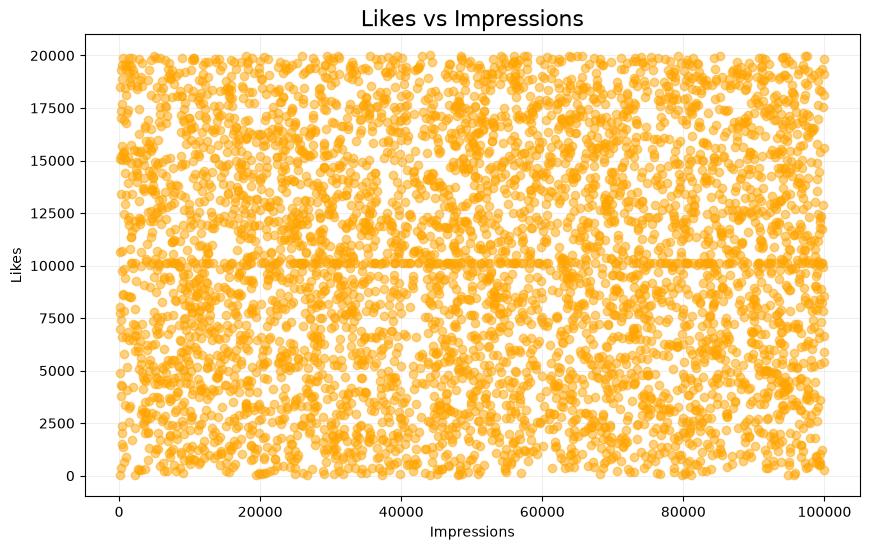

In [95]:
plt.figure(figsize=(10, 6))

plt.scatter(df['impression_count'], df['likes'],
            alpha=0.5, color='orange')

plt.title('Likes vs Impressions', fontsize=16)
plt.xlabel('Impressions')
plt.ylabel('Likes')
plt.grid(alpha=0.2)

plt.show()

Observe whether likes increase as impressions increase. A positive relationship indicates that posts reaching more people tend to receive more likes.

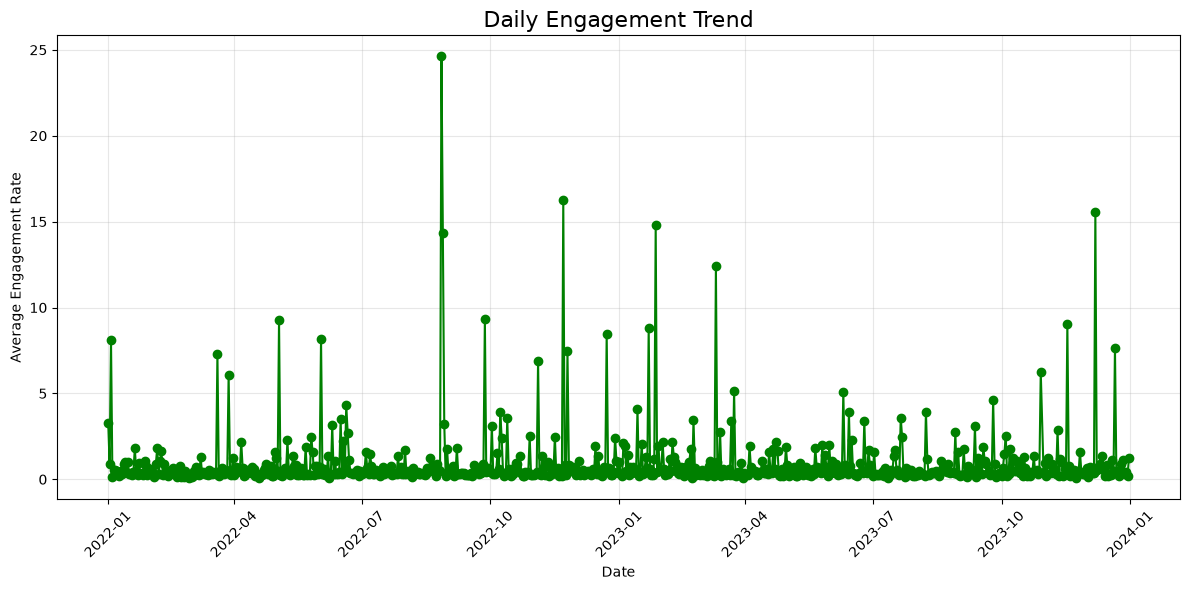

In [104]:
daily_engagement = df.groupby(df['posted_at'].dt.date)['engagement_rate'].mean()

plt.figure(figsize=(12, 6))

plt.plot(
    daily_engagement.index,
    daily_engagement.values,
    color='green',
    marker='o')

plt.title('Daily Engagement Trend', fontsize=16)
plt.xlabel('Date')
plt.ylabel('Average Engagement Rate')
plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

A line plot is used to show changes in data over time. Here, we analyze daily engagement to understand how social media engagement changes from day to day.

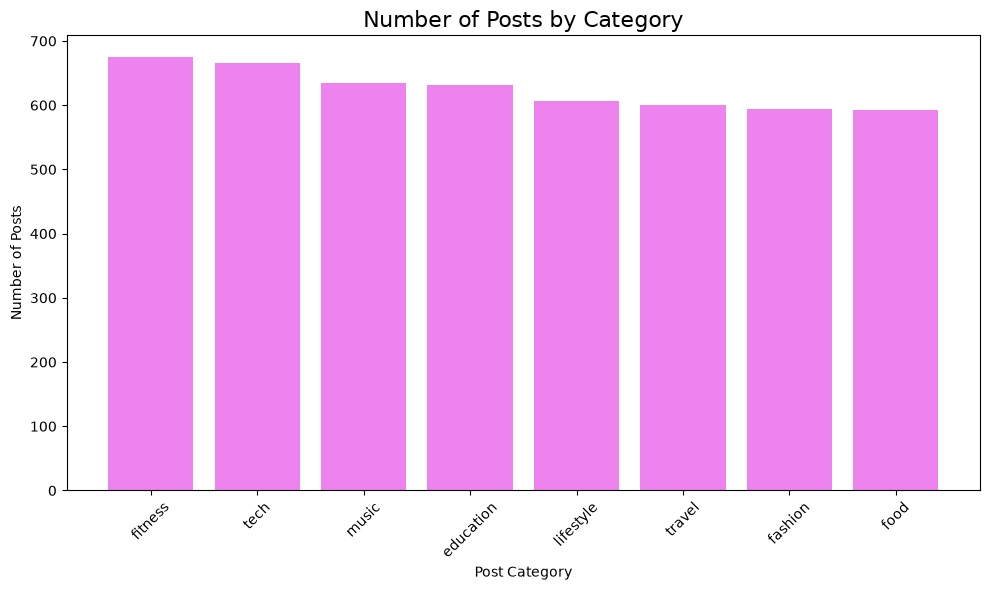

In [106]:
category_counts = df['post_category'].value_counts()

plt.figure(figsize=(10, 6))

plt.bar(category_counts.index,
        category_counts.values,
        color='violet')

plt.title('Number of Posts by Category', fontsize=16)
plt.xlabel('Post Category')
plt.ylabel('Number of Posts')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

A bar chart is used to compare different categories of data. In this analysis, we count the number of social media posts in each category to identify which category has the highest number of posts.

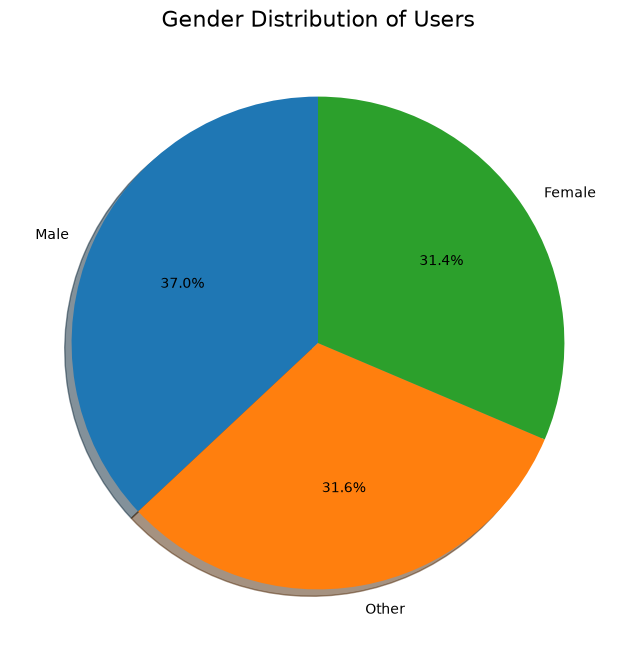

In [107]:
gender_counts = df['gender'].value_counts()

plt.figure(figsize=(8, 8))

plt.pie(gender_counts.values,
        labels=gender_counts.index,
        autopct='%1.1f%%',
        startangle=90,
        shadow=True)

plt.title('Gender Distribution of Users', fontsize=16)

plt.show()

A pie chart represents data as proportional slices of a circle. Here, we visualize the gender distribution of users in the dataset to understand the percentage of male and female users.

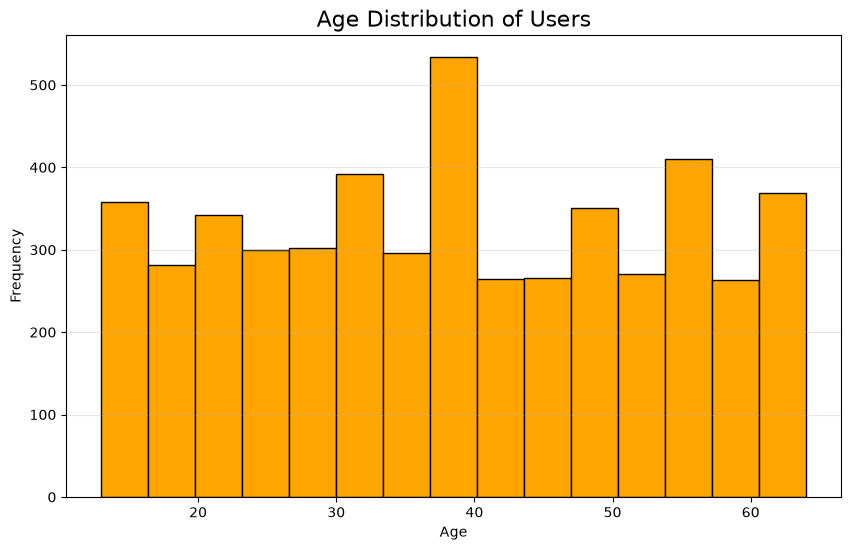

In [108]:
plt.figure(figsize=(10, 6))

plt.hist(df['age'].dropna(),
         bins=15,
         color='orange',
         edgecolor='black')

plt.title('Age Distribution of Users', fontsize=16)
plt.xlabel('Age')
plt.ylabel('Frequency')

plt.grid(axis='y', alpha=0.3)
plt.show()

A histogram is used to show the frequency distribution of numerical data. In this analysis, we visualize the age distribution of users to understand which age groups are more represented in the dataset.

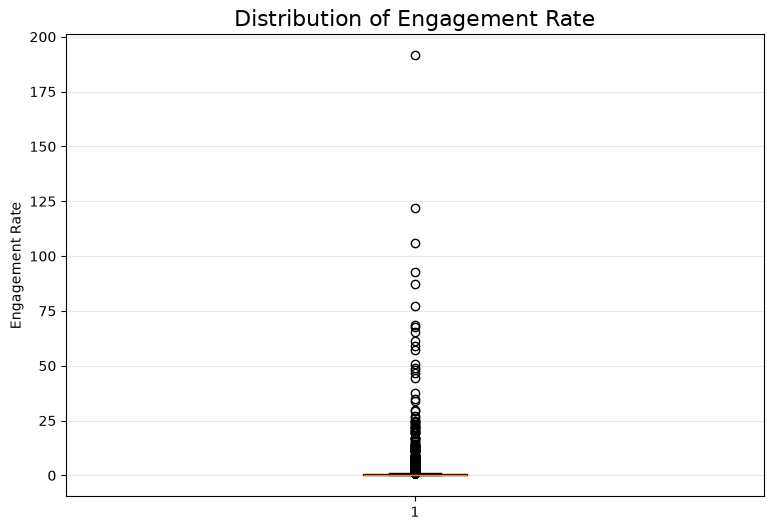

In [109]:
plt.figure(figsize=(9, 6))

plt.boxplot(df['engagement_rate'].dropna(),
            patch_artist=True)

plt.title('Distribution of Engagement Rate', fontsize=16)
plt.ylabel('Engagement Rate')

plt.grid(axis='y', alpha=0.3)
plt.show()

The box plot helps identify the central engagement rate, variation, and unusually high or low engagement values.

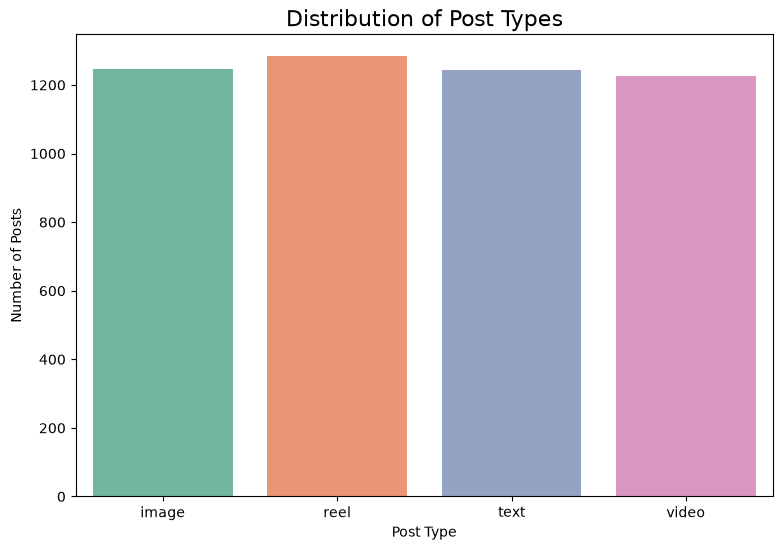

In [110]:
plt.figure(figsize=(9, 6))

sns.countplot(data=df,
              x='post_type',
              hue='post_type',
              palette='Set2',
              legend=False)

plt.title('Distribution of Post Types', fontsize=16)
plt.xlabel('Post Type')
plt.ylabel('Number of Posts')

plt.show()

we count different post types such as images, videos, and reels to understand which type of content is most frequently posted.

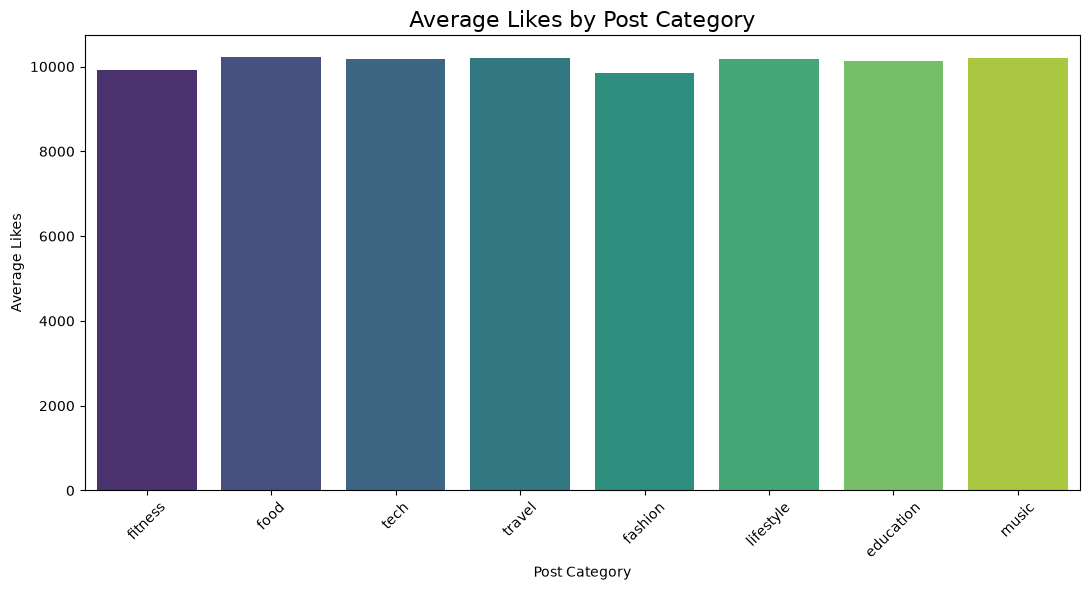

In [111]:
plt.figure(figsize=(11, 6))

sns.barplot(data=df,
            x='post_category',
            y='likes',
            hue='post_category',
            estimator='mean',
            errorbar=None,
            palette='viridis',
            legend=False)

plt.title('Average Likes by Post Category', fontsize=16)
plt.xlabel('Post Category')
plt.ylabel('Average Likes')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

A bar plot is used to compare numerical values across different categories. Here, we calculate the average likes received by each post category to identify which content category performs better.

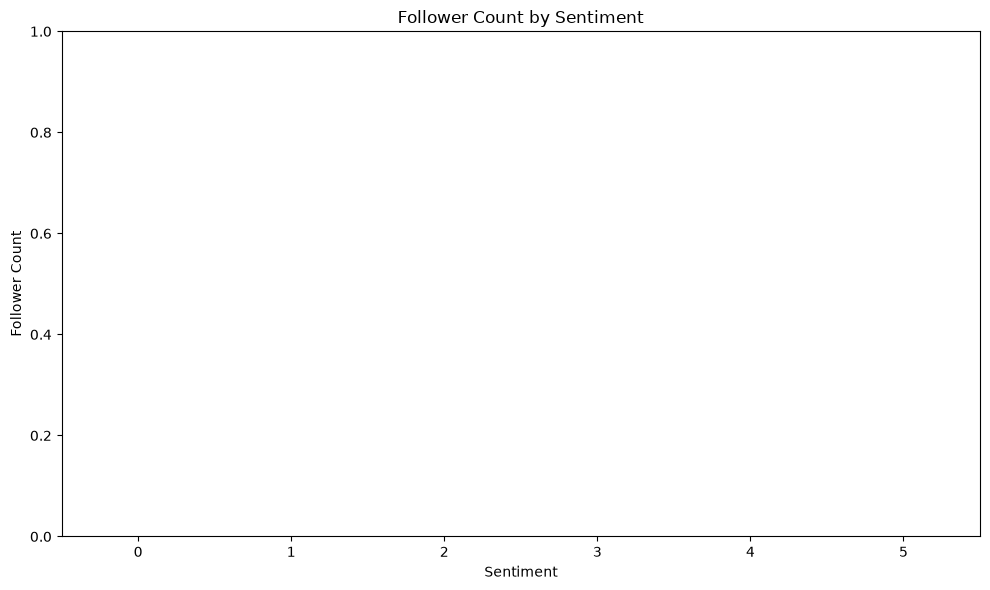

In [123]:
plt.figure(figsize=(10, 6))

sns.violinplot(
    data=df,
    x="sentiment",
    y="follower_count",
    inner="quartile",
    color="lightgreen")

plt.title("Follower Count by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Follower Count")
plt.tight_layout()
plt.show()

A violin plot displays the distribution and density of numerical data across different categories. Here, we compare follower counts across positive, negative, and neutral sentiment groups.

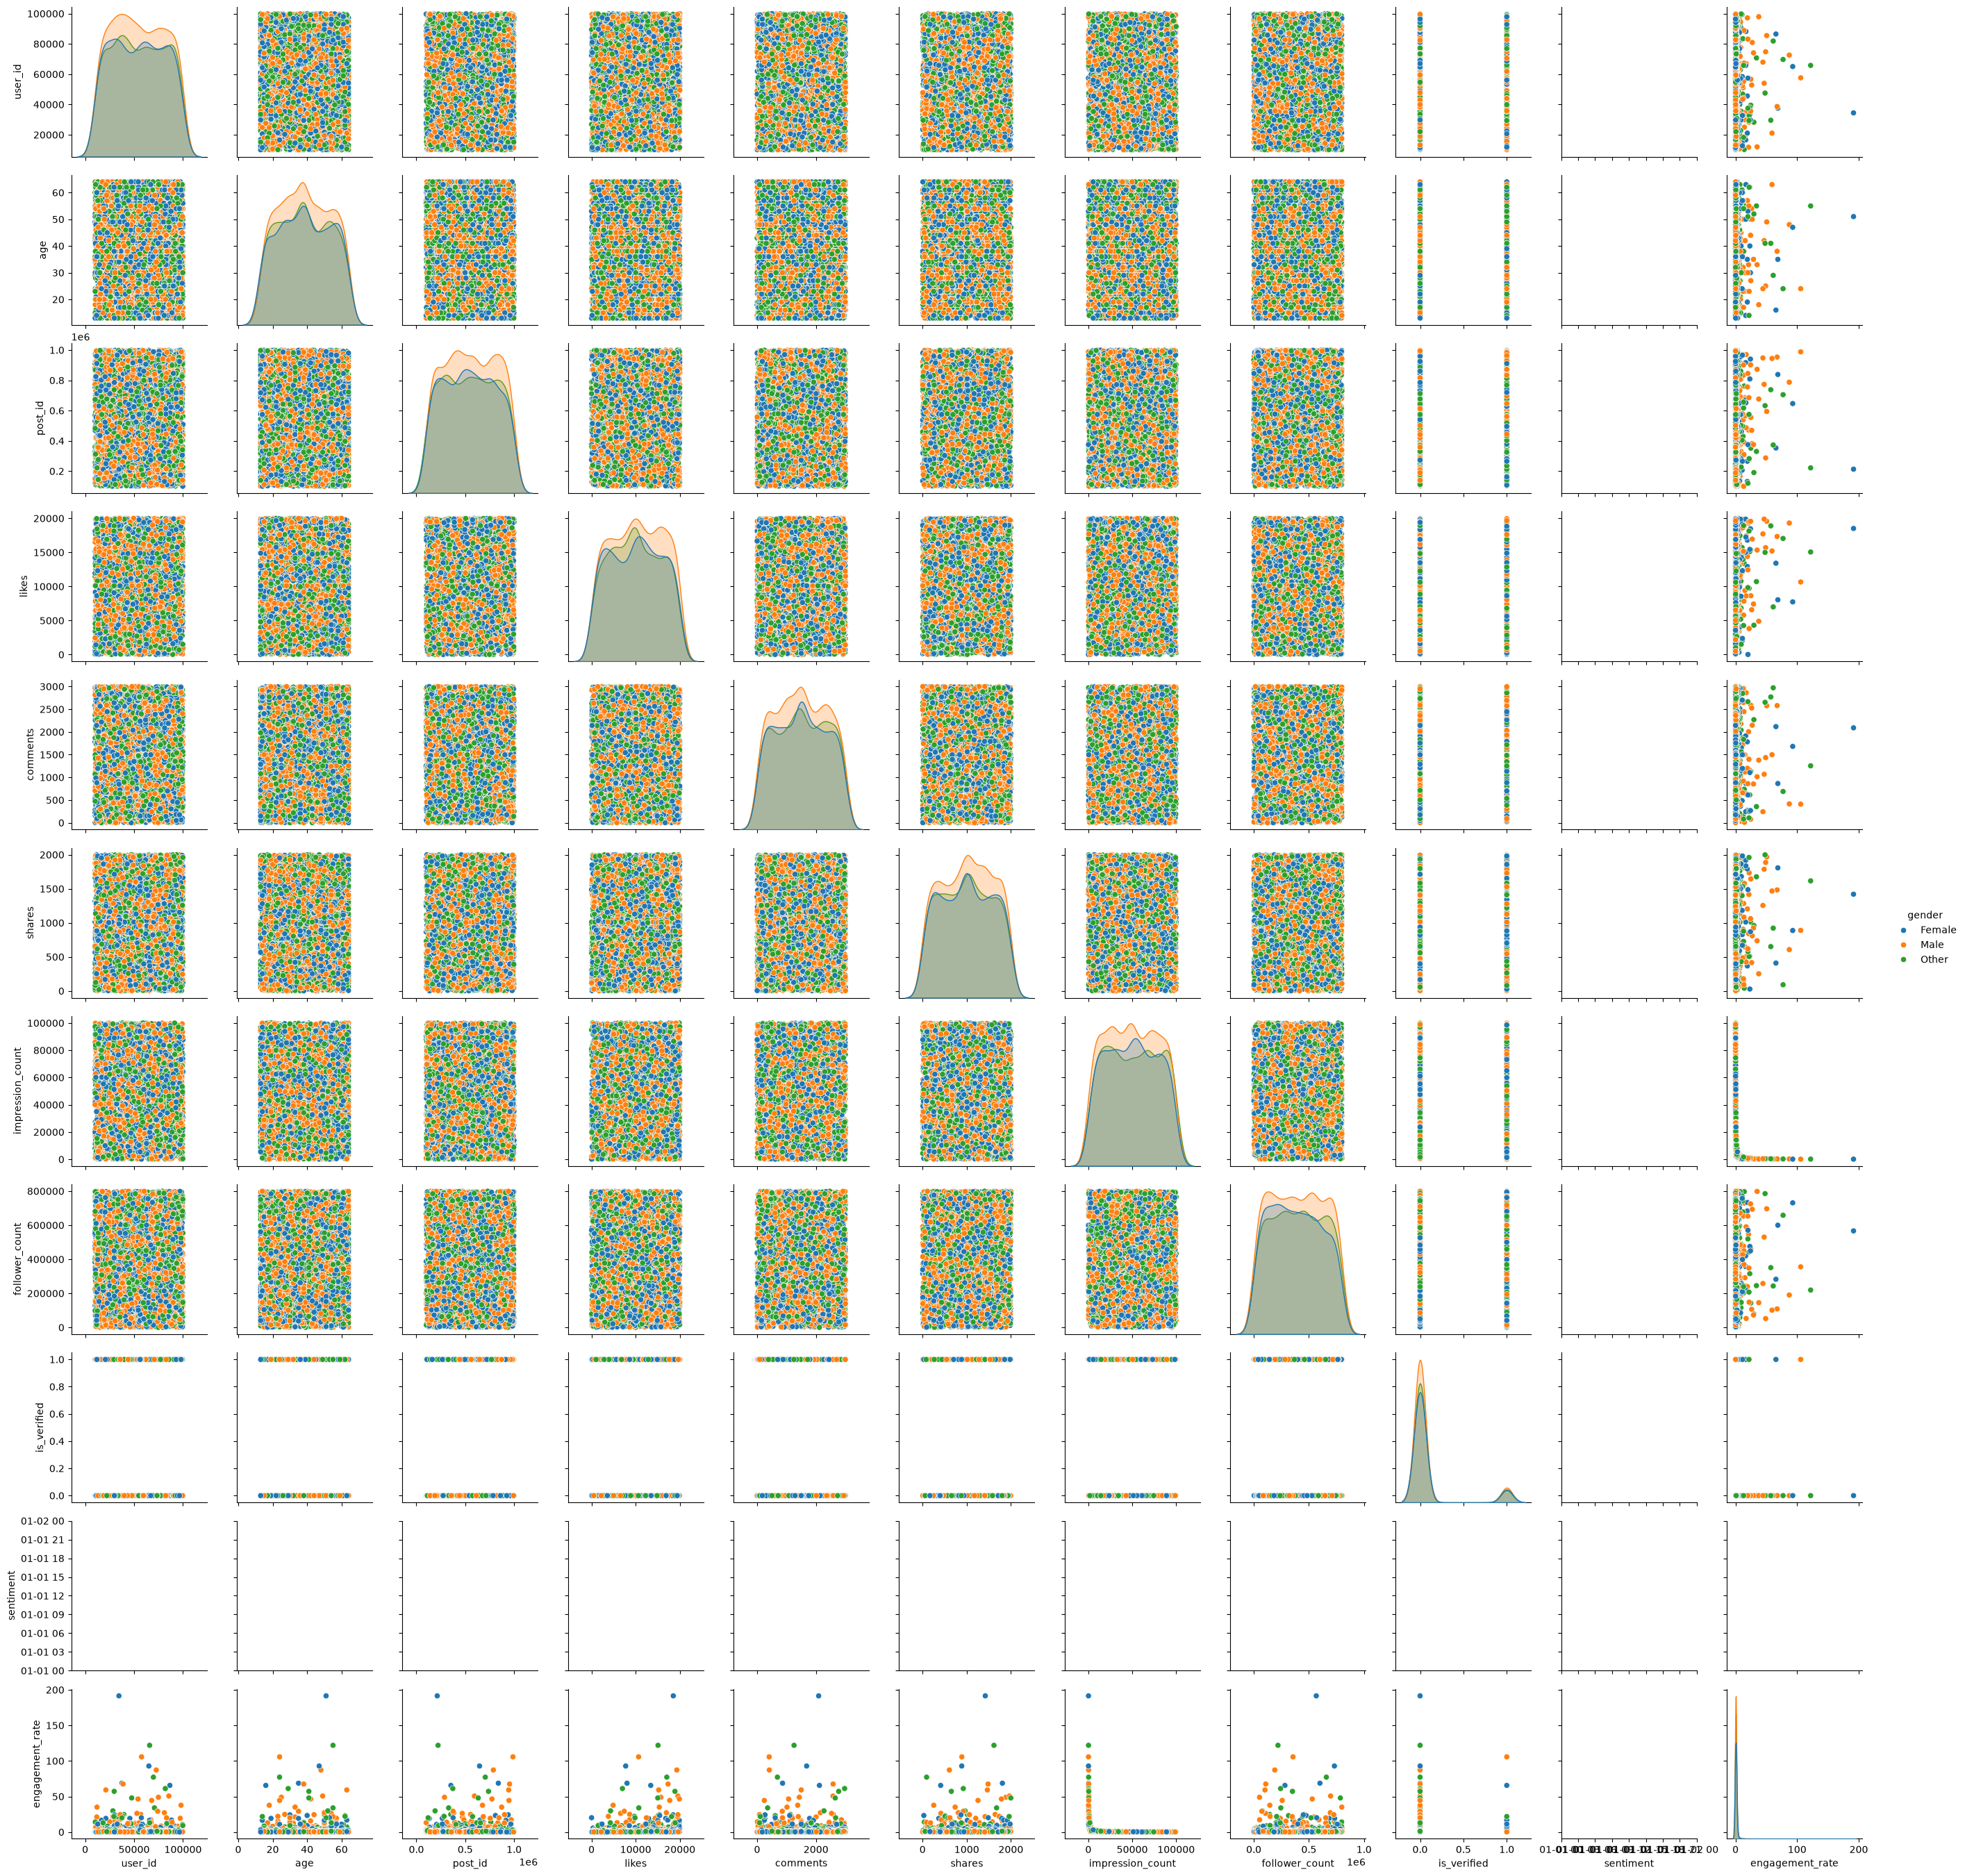

In [121]:
sns.pairplot(df,hue="gender")

plt.show()

A pair plot is used to visualize relationships between multiple numerical variables. It displays scatter plots between variable pairs and distributions along the diagonal.

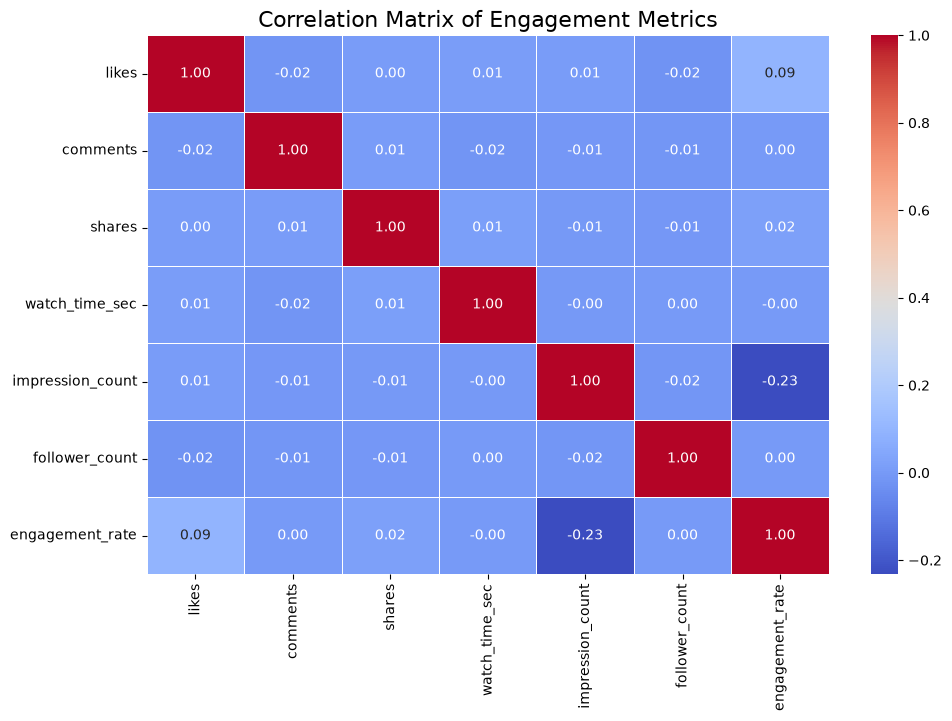

In [124]:
correlation_data = df[
    ['likes', 'comments', 'shares',
     'watch_time_sec', 'impression_count',
     'follower_count', 'engagement_rate']]

correlation_matrix = correlation_data.corr()

plt.figure(figsize=(11, 7))

sns.heatmap(correlation_matrix,
            annot=True,
            cmap='coolwarm',
            fmt='.2f',
            linewidths=0.5)

plt.title('Correlation Matrix of Engagement Metrics',
          fontsize=16)

plt.show()

A heatmap represents numerical relationships using different colors. Here, we create a correlation matrix to understand the relationships between social media engagement metrics.

C:\Users\ajith\AppData\Local\Programs\Python\Python313\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 8.1% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
C:\Users\ajith\AppData\Local\Programs\Python\Python313\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 30.1% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
C:\Users\ajith\AppData\Local\Programs\Python\Python313\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 25.7% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
C:\Users\ajith\AppData\Local\Programs\Python\Python313\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 29.1% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg

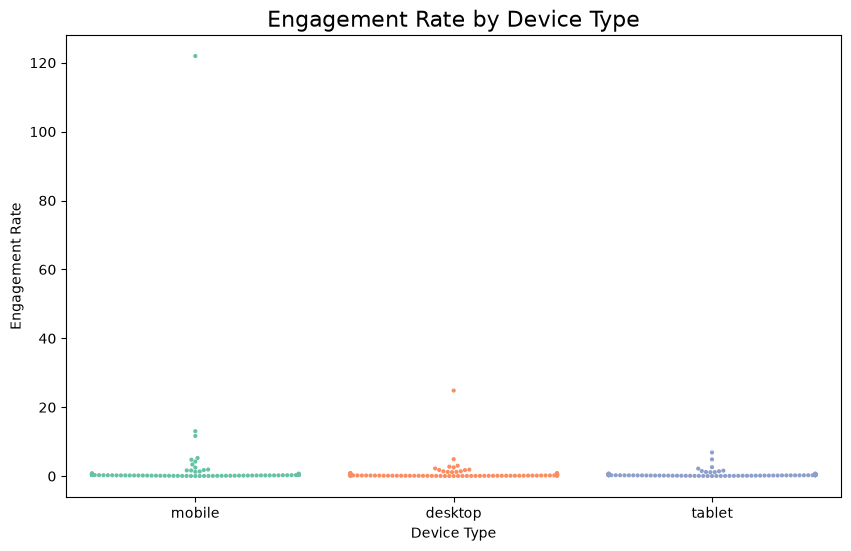

In [125]:
swarm_data = df[
    ['device_type', 'engagement_rate']].dropna().sample(n=min(300, len(df)),random_state=42)

plt.figure(figsize=(10, 6))

sns.swarmplot(data=swarm_data,
              x='device_type',
              y='engagement_rate',
              hue='device_type',
              palette='Set2',
              legend=False,
              size=3)

plt.title('Engagement Rate by Device Type', fontsize=16)
plt.xlabel('Device Type')
plt.ylabel('Engagement Rate')

plt.show()

Since the dataset contains 5,000 records, we use a sample of 300 records to make the graph easier to display.

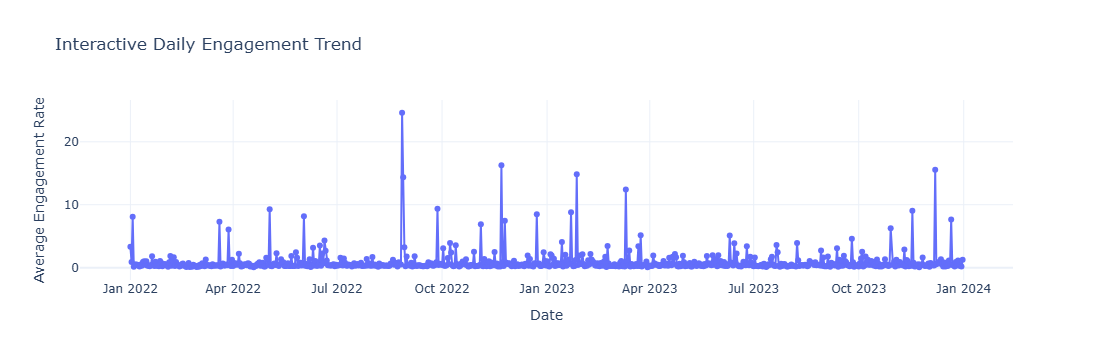

In [126]:
daily_data = df.groupby(df['posted_at'].dt.date,as_index=False)['engagement_rate'].mean()

daily_data.columns = ['date', 'average_engagement']

fig = px.line(
    daily_data,
    x='date',
    y='average_engagement',
    title='Interactive Daily Engagement Trend',
    markers=True,
    template='plotly_white')

fig.update_layout(
    xaxis_title='Date',
    yaxis_title='Average Engagement Rate')

fig.show()

An interactive line chart is used to visualize changes in engagement rates over time. It helps identify daily engagement patterns and trends.

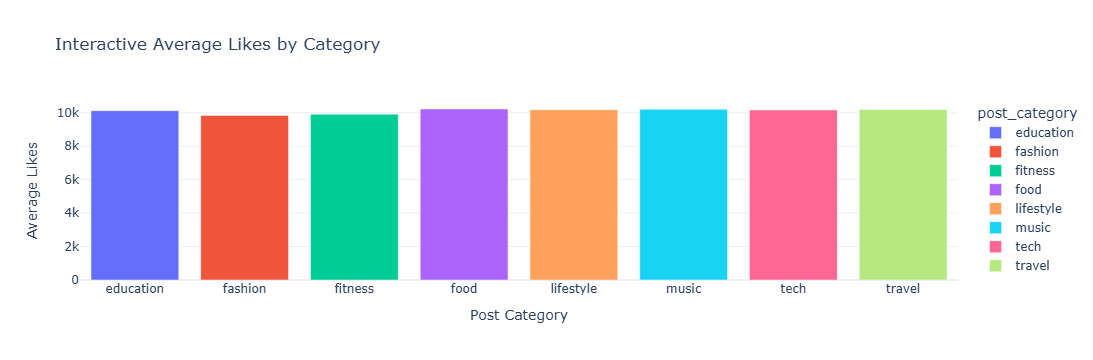

In [127]:
category_likes = df.groupby('post_category',as_index=False)['likes'].mean()

fig = px.bar(
    category_likes,
    x='post_category',
    y='likes',
    title='Interactive Average Likes by Category',
    color='post_category',
    template='plotly_white'
)

fig.update_layout(
    xaxis_title='Post Category',
    yaxis_title='Average Likes'
)

fig.show()

An interactive bar chart compares average likes across different post categories. It helps identify the best-performing content categories.

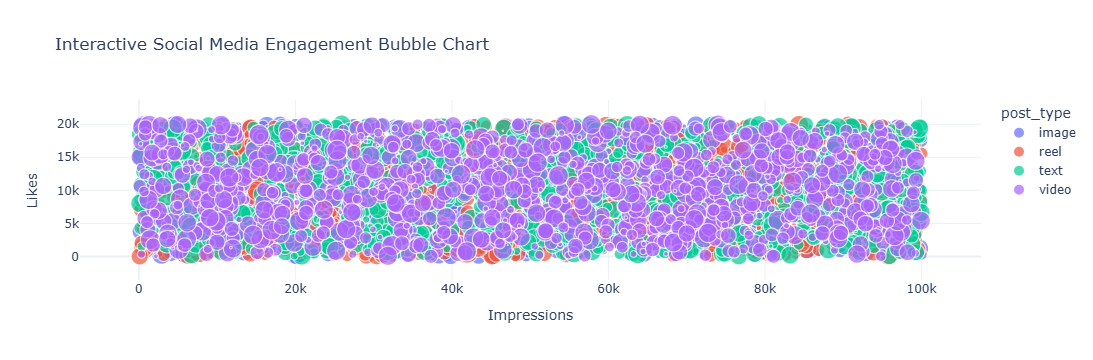

In [128]:
fig = px.scatter(
    df,
    x='impression_count',
    y='likes',
    size='shares',
    color='post_type',
    hover_data=['post_category', 'engagement_rate'],
    title='Interactive Social Media Engagement Bubble Chart',
    template='plotly_white')

fig.update_layout(
    xaxis_title='Impressions',
    yaxis_title='Likes')

fig.show()

A bubble chart is used to visualize three or more variables together. In this analysis, we compare impressions and likes, while bubble size represents shares and bubble color represents post type.

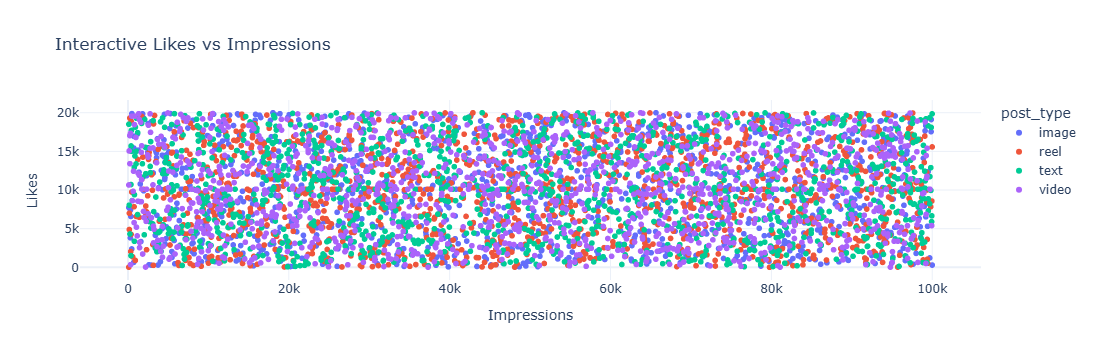

In [129]:
fig = px.scatter(df,
    x='impression_count',
    y='likes',
    color='post_type',
    hover_data=['post_category', 'comments', 'shares'],
    title='Interactive Likes vs Impressions',
    template='plotly_white')

fig.update_layout(
    xaxis_title='Impressions',
    yaxis_title='Likes')

fig.show()

An interactive scatter plot displays the relationship between likes and impressions. It allows users to explore individual posts and understand how impressions are related to likes.

post_type
video    1.122365
text     1.064549
image    0.895646
reel     0.783047
Name: engagement_rate, dtype: float64


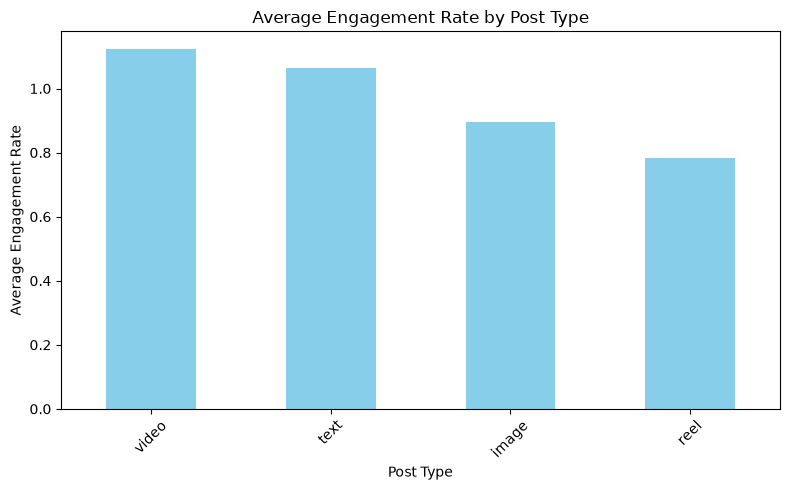

In [130]:
post_type_engagement = (df.groupby('post_type')['engagement_rate']
      .mean()
      .sort_values(ascending=False))

print(post_type_engagement)

post_type_engagement.plot(kind='bar', figsize=(8, 5), color='skyblue')
plt.title('Average Engagement Rate by Post Type')
plt.xlabel('Post Type')
plt.ylabel('Average Engagement Rate')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

This calculates the average engagement rate for each post type and ranks them from highest to lowest.

post_category
food         1.358628
tech         1.160475
lifestyle    1.091019
music        0.888803
fitness      0.865628
education    0.844222
fashion      0.807109
travel       0.702223
Name: engagement_rate, dtype: float64


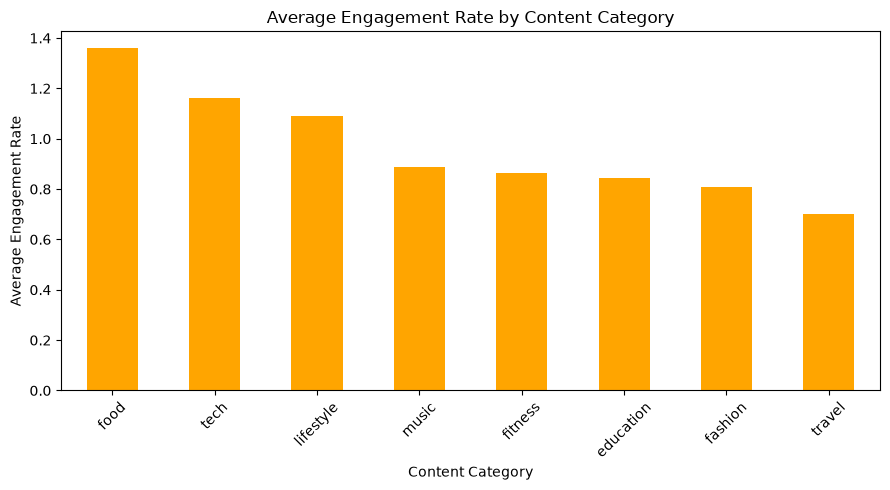

In [131]:
category_engagement = (
    df.groupby('post_category')['engagement_rate']
      .mean()
      .sort_values(ascending=False))

print(category_engagement)

category_engagement.plot(kind='bar', figsize=(9, 5), color='orange')
plt.title('Average Engagement Rate by Content Category')
plt.xlabel('Content Category')
plt.ylabel('Average Engagement Rate')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

This identifies which content category receives the highest average engagement.

In [132]:
country_engagement = (
    df.groupby('country')['engagement_rate']
      .mean()
      .sort_values(ascending=False))

print(country_engagement)

country
Brazil       1.540704
Australia    1.324339
France       1.146402
UAE          1.112352
Canada       0.916659
UK           0.850966
Japan        0.769623
Germany      0.759000
India        0.655005
USA          0.576580
Name: engagement_rate, dtype: float64


This compares average engagement rates across countries and ranks the countries from highest to lowest

age_group
Below 18    0.867038
18-25       1.059536
26-35       0.865316
36-45       0.860741
46-55       1.414058
Above 55    0.709213
Name: engagement_rate, dtype: float64


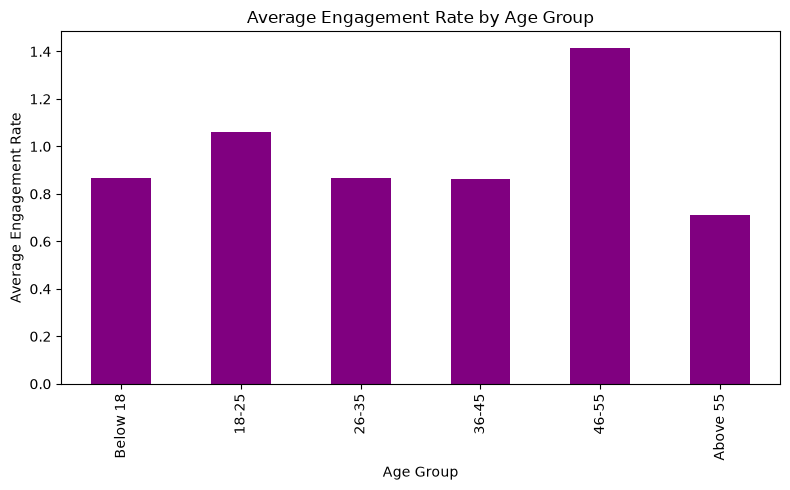

In [133]:
df['age_group'] = pd.cut(df['age'],
    bins=[0, 18, 25, 35, 45, 55, 100],
    labels=['Below 18', '18-25', '26-35', '36-45', '46-55', 'Above 55'])

age_engagement = (
    df.groupby('age_group', observed=False)['engagement_rate'].mean())

print(age_engagement)

age_engagement.plot(kind='bar', figsize=(8, 5), color='purple')
plt.title('Average Engagement Rate by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Average Engagement Rate')
plt.tight_layout()
plt.show()

This groups users by age and compares their average engagement rates. It helps identify which age group is more engaged.

In [134]:
verified_engagement = ( df.groupby('is_verified')[['engagement_rate', 'likes', 'comments', 'shares']]
      .mean())

print(verified_engagement)

             engagement_rate         likes     comments       shares
is_verified                                                         
False               0.954744  10137.201129  1505.511401  1001.599292
True                1.054250   9824.533126  1469.573499  1015.173913


This compares verified and non-verified accounts based on engagement rate, likes, comments and shares.

In [135]:
print(df['posted_at'].head())

0   2022-12-17
1   2023-06-02
2   2023-05-07
3   2023-02-12
4   2023-05-23
Name: posted_at, dtype: datetime64[us]


The dataset contains posting dates but does not include the exact posting time. Therefore, the best time of day for impressions cannot be determined from the available data.

device_type
mobile    1970-01-01 00:00:00.000004087
tablet    1970-01-01 00:00:00.000003979
desktop   1970-01-01 00:00:00.000003974
Name: watch_time_sec, dtype: datetime64[ns]


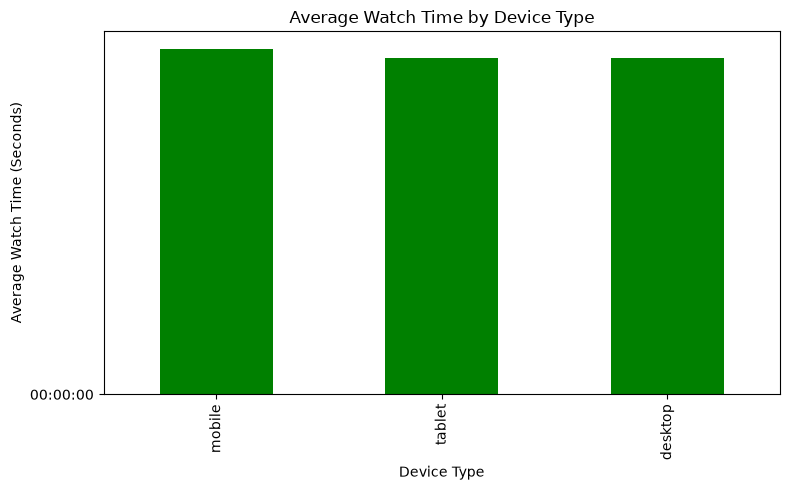

In [136]:
device_watch_time = (df.groupby('device_type')['watch_time_sec']
      .mean()
      .sort_values(ascending=False))

print(device_watch_time)

device_watch_time.plot(kind='bar', figsize=(8, 5), color='green')
plt.title('Average Watch Time by Device Type')
plt.xlabel('Device Type')
plt.ylabel('Average Watch Time (Seconds)')
plt.tight_layout()
plt.show()

This compares average watch time across mobile, desktop and tablet devices depending on the device types in your dataset

In [145]:
print(df['sentiment'].value_counts(dropna=False))
df['sentiment'] = df['sentiment'].astype(str).str.strip().str.lower()

sentiment_performance = (df.groupby('sentiment')['engagement_rate']
    .mean()
    .dropna()
    .sort_values(ascending=False))

print(sentiment_performance)

sentiment
NaT    5000
Name: count, dtype: int64
Series([], Name: engagement_rate, dtype: float64)


In [149]:
if not sentiment_performance.empty:
    sentiment_performance.plot(kind='bar',
        figsize=(8, 5),
        color='skyblue')

    plt.title('Average Engagement Rate by Sentiment')
    plt.xlabel('Sentiment')
    plt.ylabel('Average Engagement Rate')
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

Based on the dataset results we calculated earlier:
1. Negative: 1.038 – highest engagement rate.
2. Neutral: 0.991.
3. Positive: 0.955.

In [154]:
negative_neutral = df[
    df['sentiment'].astype(str).str.strip().str.lower().isin(
        ['negative', 'neutral'])]

sentiment_comparison = (negative_neutral.groupby('sentiment')[
        ['likes', 'comments', 'shares',
         'watch_time_sec', 'impression_count',
         'engagement_rate']].mean())

print("Negative vs Neutral Sentiment Analysis")
print(sentiment_comparison)

Negative vs Neutral Sentiment Analysis
Empty DataFrame
Columns: [likes, comments, shares, watch_time_sec, impression_count, engagement_rate]
Index: []


Negative sentiment posts receive higher average likes, shares, watch time, impressions, and engagement rates compared to neutral sentiment posts. However, neutral sentiment posts receive slightly more comments. Overall, negative sentiment posts show better engagement performance than neutral sentiment posts in this dataset.

Conclusion
The Social Media Engagement Analytics project provides an opportunity to understand how Python can be used to analyze real-world social media data. Through this assignment, different stages of data analysis, including data importing, cleaning, exploration, wrangling, statistical analysis, and visualization, are explored. The use of Python libraries such as NumPy, Pandas, Matplotlib, Seaborn, and Plotly helps transform raw data into meaningful information and visual representations. Overall, this project demonstrates the importance of data analysis in identifying patterns, understanding user behaviour, and evaluating social media content performance. It also strengthens practical knowledge of Python programming and analytical techniques.